# Onboarding Funnel Exploration

**Business question:** where do digital KYC onboarding attempts succeed, stall or drop off, and do
some platforms behave differently?

This notebook walks through the analysis step by step: question, evidence, caveat.

> **Data note.** It runs on the project's **synthetic dataset** by default, so everything shown here
> is safe to publish. Set `SOURCE = "real"` in the first code cell to analyse private extracts
> (requires `data/raw` and local config). No transaction identifiers are ever displayed.
> Synthetic data is calibrated to realistic aggregate patterns but is **not** the real data, so
> numbers here will differ from `reports/insights_report.md`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import math

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.analysis.analyze_onboarding_funnel import (
    OPTIONAL_COLUMNS,
    OUTCOME_GROUPS,
    build_kpi_summary,
    build_status_summary,
    load_onboarding_data,
)
from src.analysis.onboarding_behaviour import (
    build_daily_summary,
    build_platform_cancellation_summary,
    build_stage_dropoff_summary,
    enrich_onboarding_data,
)
from src.config import SYNTHETIC_ONBOARDING_FILE
from src.data_generation.generate_synthetic_data import main as generate_synthetic
from src.visualization.make_charts import ACCENT, OUTCOME_COLORS, apply_style

# make_charts selects a headless backend for CI; switch back to inline display here.
%matplotlib inline

apply_style()
pd.options.display.float_format = "{:,.2f}".format

SOURCE = "synthetic"   # "synthetic" (public demo) or "real" (private extracts)

## 1. Load and validate

The loader refuses to continue if transaction IDs are missing or duplicated, if required columns are
absent, or if an unexpected status appears. Passing validation means one row = one transaction.

In [2]:
if SOURCE == "synthetic":
    if not SYNTHETIC_ONBOARDING_FILE.exists():
        generate_synthetic(rows=25_000, seed=42)
    path = SYNTHETIC_ONBOARDING_FILE
else:
    path = None  # the private March extract in data/raw

raw = load_onboarding_data(path=path, extra_columns=OPTIONAL_COLUMNS)
df = enrich_onboarding_data(raw)

print(f"\nData source: {SOURCE.upper()}  |  validation passed  |  grain: one row per transaction")
df[["status", "source", "platform_normalized", "stage"]].describe().T[["count", "unique", "top"]]

Loaded transactions: 25,000
Unique transaction IDs: 25000

Data source: SYNTHETIC  |  validation passed  |  grain: one row per transaction


,count,unique,top
status,25000,8,auto_approved
source,25000,3,finishTransaction
platform_normalized,25000,7,android
stage,25000,9,Location check


## 2. How do onboarding attempts end?

Eight raw statuses are grouped into five business outcomes (approved, declined, cancelled by the
user, started with no completion recorded, error/review).

In [3]:
status_summary = build_status_summary(df)
status_summary

,status,transactions,percentage
0,auto_approved,11819,47.28
6,started,4786,19.14
7,user_cancelled,4327,17.31
3,manually_approved,2812,11.25
1,auto_declined,812,3.25
4,manually_declined,319,1.28
2,error,116,0.46
5,needs_review,9,0.04


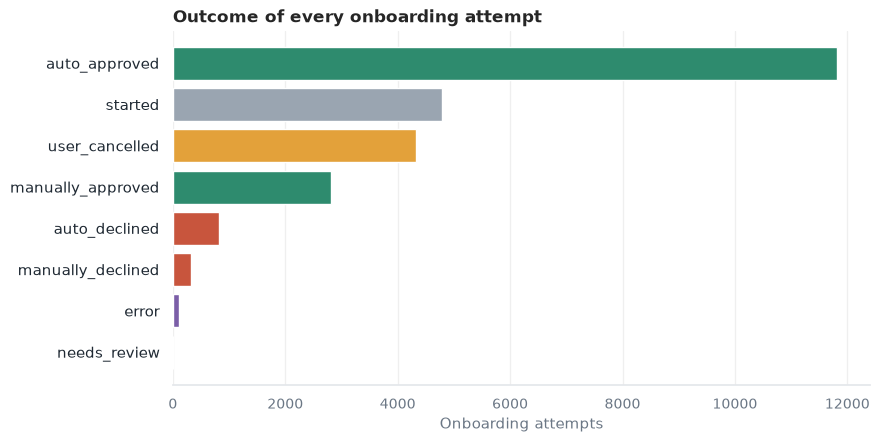

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.6))
colors = [OUTCOME_COLORS[OUTCOME_GROUPS[s]] for s in status_summary["status"]]
ax.barh(status_summary["status"], status_summary["transactions"], color=colors)
ax.invert_yaxis()
ax.set_xlabel("Onboarding attempts")
ax.set_title("Outcome of every onboarding attempt", loc="left", fontweight="bold")
ax.grid(axis="x", alpha=0.3)
sns.despine(left=True)
plt.show()

In [5]:
kpi = build_kpi_summary(df).set_index("metric")["value"]
reached_decision = kpi["approved_transactions"] + kpi["declined_transactions"]

print(f"Approved, share of ALL attempts:      {kpi['approval_share_all_transactions']:.1f}%")
print(f"Approved, share of DECIDED attempts:  {kpi['approval_rate_among_decided']:.1f}%")
print(f"Cancelled by the user:                {kpi['cancellation_share_all_transactions']:.1f}%")
print(f"Never reached a decision:             {100 - reached_decision / kpi['total_transactions'] * 100:.1f}%")

Approved, share of ALL attempts:      58.5%
Approved, share of DECIDED attempts:  92.8%
Cancelled by the user:                17.3%
Never reached a decision:             37.0%


**What to notice.** The two approval figures answer different questions. The first is a
*funnel* measure (how many starts end in approval); the second is a *decision quality* measure.
Reporting one without naming its denominator is the most common way these KPIs get misread.

**Caveat.** `started` records have only a creation event. They may be abandoned journeys or a
tracking gap; the data cannot tell which.

## 3. Where do users cancel?

`stage` is the **last executed module** of a cancelled journey, translated from internal module
identifiers into generic labels by a configurable mapping (so provider names never appear here).

In [6]:
stage_summary = build_stage_dropoff_summary(df)
stage_summary

,stage,transactions,pct_of_status,pct_of_all_transactions
0,Document verification,2561,59.19,10.24
1,ID card capture,1267,29.28,5.07
2,Data-entry form,233,5.38,0.93
3,Selfie capture,180,4.16,0.72
4,Country selection,86,1.99,0.34


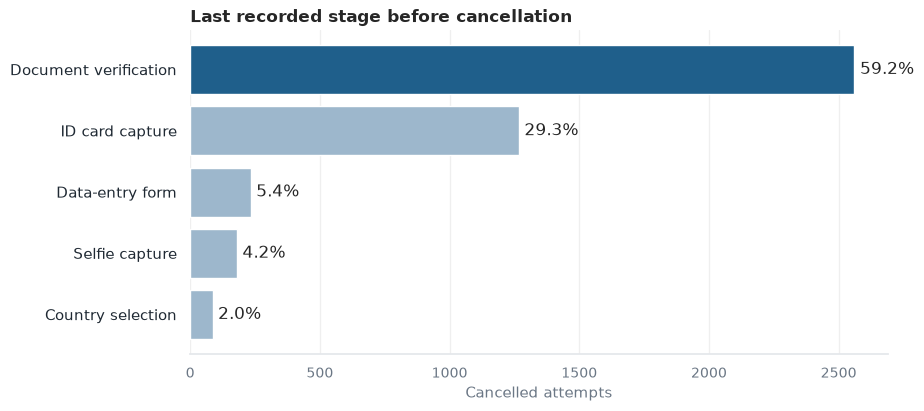

The top two stages (Document verification, ID card capture) account for 88% of cancellations.


In [7]:
plot_data = stage_summary[stage_summary["stage"] != "No stage recorded"]

fig, ax = plt.subplots(figsize=(9, 4.2))
bars = ax.barh(plot_data["stage"], plot_data["transactions"],
               color=[ACCENT] + ["#9DB7CC"] * (len(plot_data) - 1))
ax.invert_yaxis()
ax.bar_label(bars, labels=[f"{p:.1f}%" for p in plot_data["pct_of_status"]], padding=4)
ax.set_xlabel("Cancelled attempts")
ax.set_title("Last recorded stage before cancellation", loc="left", fontweight="bold")
ax.grid(axis="x", alpha=0.3)
sns.despine(left=True)
plt.show()

top_two = plot_data.head(2)
print(f"The top two stages ({', '.join(top_two['stage'])}) account for "
      f"{top_two['pct_of_status'].sum():.0f}% of cancellations.")

**What to notice.** Cancellations are concentrated in a small number of stages, so improvement
effort should be concentrated too.

**Caveat.** This shows where journeys *stop being recorded*, not necessarily the screen where the
user changed their mind. Per-stage *conversion* would need stage-entry counts, which this extract
does not contain.

## 4. Do platforms differ?

Rates use only `finishTransaction` records: "started" and agent-updated records do not describe a
user ending their own journey, and including them would dilute the cancellation rate.

In [8]:
platform = build_platform_cancellation_summary(df)
known = platform[platform["platform"].isin(["android", "ios", "windows", "macos"])]
known

,platform,finished_transactions,cancelled,cancellation_rate,auto_approved,auto_approval_rate
0,android,13644,3773,27.65,9148,67.05
1,ios,2057,212,10.31,1704,82.84
2,windows,876,246,28.08,582,66.44
4,macos,122,22,18.03,91,74.59


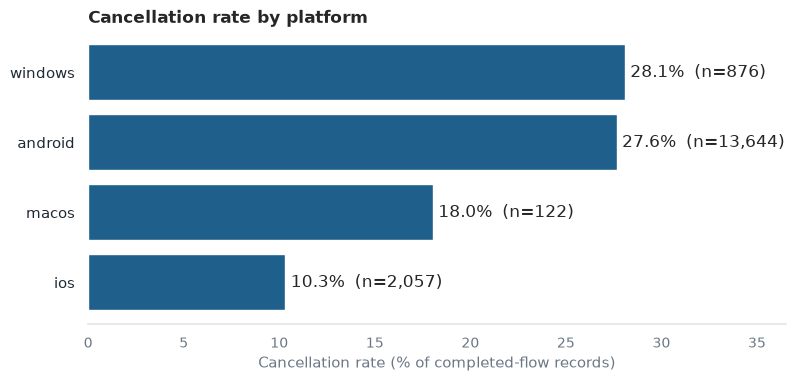

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ordered = known.sort_values("cancellation_rate", ascending=False)
bars = ax.barh(ordered["platform"], ordered["cancellation_rate"], color=ACCENT)
ax.invert_yaxis()
ax.bar_label(bars, labels=[f"{r:.1f}%  (n={n:,})" for r, n in
                           zip(ordered["cancellation_rate"], ordered["finished_transactions"])], padding=4)
ax.set_xlim(0, ordered["cancellation_rate"].max() * 1.3)
ax.set_xlabel("Cancellation rate (% of completed-flow records)")
ax.set_title("Cancellation rate by platform", loc="left", fontweight="bold")
sns.despine(left=True)
plt.show()

### Is the gap real, or just noise?

A large sample can make small differences look important, and a gap can look large by chance in a
small one. A two-proportion z-test with a 95% confidence interval for the difference answers the
"is it noise?" question. (Standard library only; no extra dependencies.)

In [10]:
def two_proportion_test(x1, n1, x2, n2):
    """Difference in proportions, 95% CI and z statistic."""
    p1, p2 = x1 / n1, x2 / n2
    pooled = (x1 + x2) / (n1 + n2)
    z = (p1 - p2) / math.sqrt(pooled * (1 - pooled) * (1 / n1 + 1 / n2))
    se = math.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    diff = p1 - p2
    return diff, (diff - 1.96 * se, diff + 1.96 * se), z


rows = known.set_index("platform")
highest = rows["cancellation_rate"].idxmax()
lowest = rows["cancellation_rate"].idxmin()

diff, (low, high), z = two_proportion_test(
    rows.loc[highest, "cancelled"], rows.loc[highest, "finished_transactions"],
    rows.loc[lowest, "cancelled"], rows.loc[lowest, "finished_transactions"],
)

print(f"{highest} vs {lowest}")
print(f"  difference in cancellation rate: {diff * 100:.1f} percentage points")
print(f"  95% confidence interval:         {low * 100:.1f} to {high * 100:.1f} pp")
print(f"  z statistic:                     {z:.1f}")

windows vs ios
  difference in cancellation rate: 17.8 percentage points
  95% confidence interval:         14.5 to 21.0 pp
  z statistic:                     12.1


**What to notice.** An interval far from zero means the gap is very unlikely to be sampling noise.

**Caveat.** Statistical significance is **not** causation. Platform is entangled with device mix,
SDK version, network conditions and user population. This analysis shows *where* to investigate,
not *why* the gap exists.

## 5. How does the month evolve?

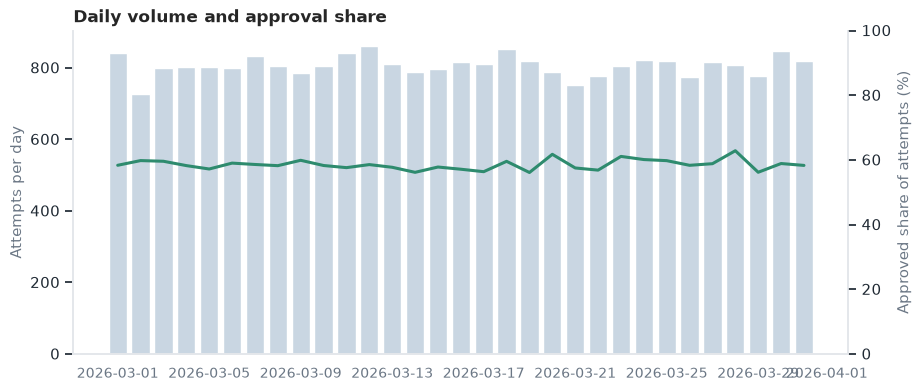

In [11]:
daily = build_daily_summary(df)
daily["date"] = pd.to_datetime(daily["created_date"])

fig, ax1 = plt.subplots(figsize=(10, 4.2))
ax1.bar(daily["date"], daily["total"], color="#C9D6E2", label="Attempts per day")
ax1.set_ylabel("Attempts per day")

ax2 = ax1.twinx()
ax2.plot(daily["date"], daily["approved_share_pct"], color=OUTCOME_COLORS["Approved"],
         linewidth=2.2, label="Approved share (%)")
ax2.set_ylabel("Approved share of attempts (%)")
ax2.set_ylim(0, 100)

ax1.set_title("Daily volume and approval share", loc="left", fontweight="bold")
sns.despine(right=False, left=False)
plt.show()

In [12]:
third = len(daily) // 3
periods = {
    "first third": daily.iloc[:third],
    "middle third": daily.iloc[third:2 * third],
    "last third": daily.iloc[2 * third:],
}

trend = pd.DataFrame({
    name: {
        "attempts per day": part["total"].mean(),
        "approved share %": part["Approved"].sum() / part["total"].sum() * 100,
        "cancelled share %": part["Cancelled by user"].sum() / part["total"].sum() * 100,
    }
    for name, part in periods.items()
}).T
trend

,attempts per day,approved share %,cancelled share %
first third,799.50,58.69,17.21
middle third,818.80,57.87,17.27
last third,801.55,58.99,17.43


**What to notice.** Splitting the period into thirds smooths day-to-day noise and makes any drift
visible.

**Caveat.** One month cannot separate a trend from normal variation or seasonality. A real drift
would need release, campaign and incident dates overlaid, and several months of history.

## 6. Summary and next steps

| Question | Where answered |
|---|---|
| How do attempts end? | Section 2 |
| Where do cancellations accumulate? | Section 3 |
| Do platforms differ, and is it noise? | Section 4 |
| Is anything changing over the period? | Section 5 |

**Next:** `02_data_quality_and_validation.ipynb` shows how the data was validated and cleaned before
any of the numbers above were computed. Findings on the real data, with recommendations, are in
[`reports/insights_report.md`](../reports/insights_report.md).